# Machine-Learning Screening for Preeclampsia Clinical-Trial Enrichment
## Seven classical classifiers and a proposed multi-time-point training method

**About this notebook.** Preventive trials in preeclampsia need to enrol women at high risk, because the disease is uncommon and a trial of unselected women would have to be very large. Accurate first-trimester screening relies on biomarkers and Doppler ultrasound that are not routinely available, whereas routine antenatal data (blood pressure, standard laboratory tests and maternal history) are collected at every visit. This notebook develops and evaluates machine-learning models that use only routine antenatal data to identify, at the 28-week visit, normotensive women at high risk of subsequently developing preeclampsia, so that they can be selected for a preventive trial.

The analysis has three parts. First, seven classical classifiers (Logistic Regression, Decision Tree, Random Forest, Support Vector Machine, K-Nearest Neighbours, Naive Bayes and Gradient Boosting) are compared using features from the 28-week visit, with nested cross-validation, the area under the precision–recall curve (PR-AUC) as the primary measure, and strict control of information leakage. Second, a proposed method, **multi-time-point (MTP) training**, is applied to the best baseline classifier: the classifier is trained on observations from all antenatal visits (weeks 25–34) of the training participants, which greatly increases the number of positive examples, while predictions are still made from the 28-week visit only. Third, MTP training is applied to all seven classifiers, and the results are checked on a held-out test set, as a top-10% screening rule, and in sensitivity analyses.

**Data source.** Jhee JH, Lee S, Park Y, et al. *Prediction model development of late-onset preeclampsia using machine learning-based methods.* PLOS ONE. 2019;14(8):e0221202. Supporting information S1 Data (`pone.0221202.s002.xlsx`), distributed under a CC BY 4.0 licence.

**Study design.** Screening is framed as a two-stage process at the 28-week antenatal visit.
1. *Eligibility (rule-based):* women who are normotensive at the visit (systolic blood pressure < 140 mmHg and diastolic blood pressure < 90 mmHg) are eligible for screening.
2. *Risk stratification (machine learning):* among eligible women, classifiers estimate the risk of subsequently developing preeclampsia; the highest-risk women would be selected for a preventive clinical trial.

**Analysis overview**

| Section | Content |
| --- | --- |
| 1 | Computing environment |
| 2 | Data source and loading |
| 3 | Data structure |
| 4 | Variable translation and coding |
| 5 | Reconstruction of participants and removal of duplicate records |
| 6 | Study population and eligibility |
| 7 | Feature selection and leakage control |
| 8 | Descriptive statistics |
| 9 | Development and test sets |
| 10 | Evaluation protocol |
| 11 | Baseline classifiers |
| 12 | Selection of the reference model |
| 13 | Proposed method: multi-time-point (MTP) training |
| 14 | Secondary analysis: MTP training across all seven classifiers |
| 15 | Evaluation on the held-out test set |
| 16 | Screening threshold and confusion matrices |
| 17 | Calibration |
| 18 | Feature importance |
| 19 | Sensitivity analyses |
| 20 | Summary of findings |

## 1. Computing environment

All analyses were performed in Python using scikit-learn for modelling and evaluation, pandas and NumPy for data handling, SciPy for statistical testing, and Matplotlib and seaborn for visualisation. A fixed random seed (42) is used for every data split, resampling procedure and stochastic model so that all results are reproducible. The data file is expected at `../data/raw/pone.0221202.s002.xlsx` relative to this notebook.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, brier_score_loss, f1_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from joblib import Parallel, delayed

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
DATA_PATH = "../data/raw/pone.0221202.s002.xlsx"
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1


## 2. Data source and loading

The `Data` worksheet of the S1 Data file contains two header rows: English variable codes in the first row and Korean variable labels in the second. The English codes are used as column names; the Korean labels are retained separately to document the meaning of each variable (Section 4). One empty column is removed.

In [2]:
raw = pd.read_excel(DATA_PATH, sheet_name="Data", header=0, skiprows=[1])
raw = raw.loc[:, ~raw.columns.astype(str).str.startswith("Unnamed")]
korean = pd.read_excel(DATA_PATH, sheet_name="Data", header=None, nrows=2).T.set_index(0)[1]
print("Rows:", raw.shape[0], "| Columns:", raw.shape[1])
raw.head()

Rows: 42965 | Columns: 112


,number,(rev) dur_week,dur_week,PREG_WK,TGT,AL,ALK,ALT,AST,BUN,CAL,CHOL,CR_SE,CRP,ESR,Gamma,Glu,Hb,K,Mg,PLT,Tbil,Tco2,Tpro,Uric,Urine_AC,Urine_PC,WBC,SBP,DBP,PROTEIN,CHK,D1CEFO04,D2GEST01,D2KLIM01,D2LACT07,D2MEDI01,D2MUCO02,D2PORT01,D3BOLG01,D1KERO01,D1UBAC01,D2SOLO01,D2AIRT01,D2ALAX01,D2BEAR01,D2SYNT01,D2CARO02,D2DULC01,D2TYLE01,D2UNID01,D2WITH01,D1LASI02,D2LASI01,D2NORV01,D2HYDR01,D2ALDA01,D2ADAL02,D2COZA01,D2TEPR01,D2ADAL03,D1ALBU03,D2DILA02,D2DILA01,D2AMOD01,D2DICH01,D2COZA03,D2KEYD01,D1ALBU02,D2ATAC03,D2CONC04,D2DIOV01,D2ATAC01,A0035967,A0035968,A0036023,T3_1_1,T3_1_2,T3_1_3,T3_2_1,T3_2_2,T3_2_3,T3_2_4,T3_3_1,T3_3_2,T3_3_3,T3_3_4,T3_3_5,T3_3_6,T3_3_7,T3_4_2,T3_4_3,T3_4_4,T3_4_5,T3_4_6,T3_5_1,T3_5_2,T3_5_3,T3_5_4,T3_5_5,T3_5_6,T3_5_7,T3_5_8,CASE01,CASE02,CASE03,CASE04,CASE05,CASE08,CASE09,CASE11,CASE12
0,1,36.0,36.0,29,0,1.365829,25.979899,7.979899,10.844221,4.701508,3.095477,95.105528,0.271910,2.819211,5.432161,0.070352,46.422111,0.233668,1.595477,0.126080,162.698492,0.164322,7.201005,2.395477,1.498492,35.223104,0.253166,7.426332,113.000000,74.00000,14.703518,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,158.0,47.000000,40.0,1,1,1,1,1,1,1,1,1,2,1,2,1,1,0,0,2,2,1,1,1,1,1,1,0,0,1,0,0,0,0,0,0
1,2,36.0,36.0,33,0,1.698741,46.916877,6.729323,9.411028,4.682161,4.140554,118.806045,0.320980,1.611801,3.186398,0.083123,54.984887,0.206297,2.152141,0.057280,167.727500,0.230479,10.309824,3.023250,1.930982,12.093224,0.119547,7.415315,113.000000,71.00000,8.008816,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,158.0,48.700000,40.0,1,1,1,1,1,1,1,1,1,2,1,2,1,1,0,0,2,2,1,1,1,1,1,1,0,0,1,0,0,0,0,0,0
2,3,39.0,39.0,25,0,3.900000,51.000000,13.000000,17.000000,9.200000,8.200000,176.000000,0.700000,0.971920,1.604502,0.633441,90.000000,0.053055,0.514469,0.005563,228.000000,0.400000,2.429260,6.500000,3.800000,0.404148,0.012235,9.450000,112.285714,66.87259,0.555466,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,160.0,60.735464,60.0,1,1,1,1,1,1,1,1,1,1,1,4,2,2,0,1,1,1,1,1,1,1,1,1,0,0,1,0,0,0,0,0,0
3,4,39.0,39.0,27,0,0.889062,16.174479,4.483117,5.935065,2.830130,2.070312,55.432292,0.174000,3.532307,2.067708,0.549479,30.127604,0.239844,1.054167,0.053880,195.671795,0.115365,4.601562,1.563939,0.988281,1.096771,0.109609,8.205547,94.000000,50.00000,6.240625,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,160.0,66.800000,60.0,1,1,1,1,1,1,1,1,1,1,1,4,2,2,0,1,1,1,1,1,1,1,1,1,0,0,1,0,0,0,0,0,0
4,5,39.0,39.0,31,0,1.330052,29.689119,15.808786,13.426357,3.852850,2.988083,84.248705,0.287902,2.420697,3.691710,0.461140,47.950777,0.259326,1.845078,0.070337,136.661499,0.199741,8.821244,2.318863,1.370725,1.879171,0.142461,6.060415,101.000000,63.00000,8.716580,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,160.0,68.000000,60.0,1,1,1,1,1,1,1,1,1,1,1,4,2,2,0,1,1,1,1,1,1,1,1,1,0,0,1,0,0,0,0,0,0


## 3. Data structure

The file contains 42,965 records, whereas the original study reports 11,006 women. Each record represents a woman at a single gestational week (`PREG_WK`, weeks 25–34), so most women contribute several records. The column `number` is a record counter, and no patient identifier is provided. The outcome `TGT` indicates whether the woman developed preeclampsia. The table below shows the number of records and the outcome rate at each gestational week.

In [3]:
print("Unique values of 'number':", raw["number"].nunique(), "(record counter; no patient identifier)")
print("Outcome TGT (1 = preeclampsia):", raw["TGT"].value_counts().to_dict(),
      f"-> {raw['TGT'].mean():.2%} of records")
raw.groupby("PREG_WK")["TGT"].agg(records="size", cases="sum", rate="mean").round(3).T

Unique values of 'number': 42965 (record counter; no patient identifier)
Outcome TGT (1 = preeclampsia): {0: 40936, 1: 2029} -> 4.72% of records


PREG_WK,25,26,27,28,29,30,31,32,33,34
records,3258.000,2801.000,2492.000,3312.00,3942.000,4056.000,4422.000,5441.000,6241.000,7000.000
cases,107.000,138.000,106.000,131.00,139.000,184.000,209.000,245.000,354.000,416.000
rate,0.033,0.049,0.043,0.04,0.035,0.045,0.047,0.045,0.057,0.059


## 4. Variable translation and coding

The dataset contains five groups of variables:
- **Blood pressure:** systolic (`SBP`) and diastolic (`DBP`) blood pressure in mmHg.
- **Laboratory measurements (24):** including creatinine (`CR_SE`), uric acid (`Uric`), blood urea nitrogen (`BUN`), platelet count (`PLT`) and urine protein-to-creatinine ratio (`Urine_PC`).
- **Maternal history (`T3_*`, 27 items):** anthropometry, lifestyle, medical, obstetric and family history.
- **Medications and procedures (`D*`, `A*`):** prescription counts without dates.
- **Other:** undocumented indicators (`CASE01`–`CASE12`) and gestational age at delivery (`dur_week`, `(rev) dur_week`).

The maternal history variables were renamed in English according to their Korean labels (table below). Binary history items are coded 1 and 2 in the source file; based on their prevalence and their association with the outcome, these were interpreted as 1 = no and 2 = yes, and recoded to 0 = no and 1 = yes. Count variables (numbers of deliveries, children, stillbirths and miscarriages) and anthropometric measurements were kept on their original scales.

In [4]:
HISTORY_NAMES = {
    "T3_1_1": "height_cm", "T3_1_2": "weight_kg", "T3_1_3": "weight_at_visit_kg",
    "T3_2_1": "smoking", "T3_2_2": "alcohol", "T3_2_3": "drug_allergy", "T3_2_4": "allergic_disease",
    "T3_3_1": "chronic_hypertension", "T3_3_2": "diabetes", "T3_3_3": "hepatitis", "T3_3_4": "tuberculosis",
    "T3_3_5": "thyroid_disease", "T3_3_6": "previous_surgery", "T3_3_7": "previous_transfusion",
    "T3_4_2": "n_normal_deliveries", "T3_4_3": "n_preterm_deliveries", "T3_4_4": "n_children",
    "T3_4_5": "n_stillbirths", "T3_4_6": "n_miscarriages",
    "T3_5_1": "family_hypertension", "T3_5_2": "family_diabetes", "T3_5_3": "family_hepatitis",
    "T3_5_4": "family_tuberculosis", "T3_5_5": "family_cancer", "T3_5_6": "family_cerebrovascular",
    "T3_5_7": "history_preterm_birth", "T3_5_8": "history_preeclampsia",
}
dictionary = pd.DataFrame({"code": list(HISTORY_NAMES), "korean_label": [korean[c] for c in HISTORY_NAMES],
                           "english_name": list(HISTORY_NAMES.values())})
dictionary

,code,korean_label,english_name
0,T3_1_1,T3_1_1 키,height_cm
1,T3_1_2,T3_1_2 체중,weight_kg
2,T3_1_3,T3_1_3 내원시 체중,weight_at_visit_kg
3,T3_2_1,T3_2_1 환자-흡연,smoking
4,T3_2_2,T3_2_2 환자-술,alcohol
5,T3_2_3,T3_2_3 약물 알레르기,drug_allergy
6,T3_2_4,T3_2_4 알레르기질환,allergic_disease
7,T3_3_1,T3_3_1 고혈압여부,chronic_hypertension
8,T3_3_2,T3_3_2 당뇨여부,diabetes
9,T3_3_3,T3_3_3 간염여부,hepatitis


In [5]:
LABS = ["AL", "ALK", "ALT", "AST", "BUN", "CAL", "CHOL", "CR_SE", "CRP", "ESR", "Gamma", "Glu", "Hb",
        "K", "Mg", "PLT", "Tbil", "Tco2", "Tpro", "Uric", "Urine_AC", "Urine_PC", "WBC", "PROTEIN"]
YES_NO = [v for v in HISTORY_NAMES.values() if not v.startswith(("n_", "height", "weight"))]

df = raw.rename(columns=HISTORY_NAMES).copy()
print("Values of binary items before recoding:", sorted(pd.unique(df[YES_NO].values.ravel())))
df[YES_NO] = (df[YES_NO] == 2).astype(int)
print("After recoding:", sorted(pd.unique(df[YES_NO].values.ravel())))

Values of binary items before recoding: [np.int64(1), np.int64(2)]
After recoding: [np.int64(0), np.int64(1)]


## 5. Reconstruction of participants and removal of duplicate records

Because the file has no patient identifier, records belonging to the same woman cannot be linked directly. Inspection showed that some women were entered more than once at the same gestational week: these records share identical history and blood-pressure values and differ only in laboratory values. If such copies were allocated to both training and evaluation data, model performance would be overestimated.

Two keys were therefore constructed:
- **Participant profile (`profile`):** all 27 history items together with gestational age at delivery. Records with the same profile are treated as belonging to the same woman. This definition is conservative: distinct women with identical histories are grouped together, which can only make data splits stricter. Gestational age at delivery is used solely for this purpose and never as a feature.
- **Visit key:** profile, gestational week and systolic and diastolic blood pressure. Records sharing a visit key are treated as repeated entries of one visit, and only the first is retained.

In [6]:
history_cols = list(HISTORY_NAMES.values())
df["profile"] = pd.factorize(pd.util.hash_pandas_object(
    df[history_cols + ["dur_week"]].round(4).fillna(-999), index=False))[0]
visit_key = pd.util.hash_pandas_object(df[["profile", "PREG_WK", "SBP", "DBP"]].round(4), index=False)

example = df[visit_key.duplicated(keep=False) & (df["TGT"] == 1)].sort_values("number")
print("Example of repeated entries for one woman (identical blood pressure, differing laboratory values):")
display(example[["number", "PREG_WK", "SBP", "DBP", "Hb", "CHOL", "TGT"]].head(4))

visits = df.loc[~visit_key.duplicated()].copy()
print(f"Records: {len(df):,} -> unique visits: {len(visits):,} ({len(df) - len(visits):,} duplicates removed)")
print(f"Distinct participant profiles: {visits['profile'].nunique():,}")

Example of repeated entries for one woman (identical blood pressure, differing laboratory values):


,number,PREG_WK,SBP,DBP,Hb,CHOL,TGT
27209,27210,27,112.50000,67.535714,5.35,198.666667,1
27210,27211,27,112.50000,67.535714,5.35,198.666667,1
27211,27212,28,111.90625,70.281250,5.40,247.400000,1
27212,27213,28,111.90625,70.281250,5.40,247.400000,1


Records: 42,965 -> unique visits: 31,779 (11,186 duplicates removed)
Distinct participant profiles: 22,958


## 6. Study population and eligibility

The screening time point was fixed at the 28-week antenatal visit, so that all features are available when the prediction is made. Women were eligible if they were normotensive at this visit (systolic blood pressure < 140 mmHg and diastolic blood pressure < 90 mmHg). Women with blood pressure at or above these thresholds already meet the blood-pressure criterion for a hypertensive disorder of pregnancy and would require clinical management rather than recruitment to a preventive trial.

Three data objects are created:
- `eligible_bp`: an indicator of normotension for every unique visit.
- `pooled_visits`: all eligible visits at weeks 25–34, used only as additional training data for the proposed method (Section 13).
- `cohort`: eligible visits at week 28, one record per woman. This is the study population on which every model is evaluated.

In [7]:
eligible_bp = (visits["SBP"] < 140) & (visits["DBP"] < 90)
pooled_visits = visits[eligible_bp].copy()
cohort = pooled_visits[pooled_visits["PREG_WK"] == 28].copy()

flow = pd.DataFrame({
    "Stage": ["Records at 28 weeks", "Unique women at 28 weeks", "Eligible (SBP < 140 and DBP < 90 mmHg)"],
    "Women": [int((df["PREG_WK"] == 28).sum()), int((visits["PREG_WK"] == 28).sum()), len(cohort)],
    "Preeclampsia cases": [int(df.loc[df["PREG_WK"] == 28, "TGT"].sum()),
                           int(visits.loc[visits["PREG_WK"] == 28, "TGT"].sum()), int(cohort["TGT"].sum())],
})
flow["Prevalence"] = (flow["Preeclampsia cases"] / flow["Women"]).map("{:.2%}".format)
flow

,Stage,Women,Preeclampsia cases,Prevalence
0,Records at 28 weeks,3312,131,3.96%
1,Unique women at 28 weeks,2550,82,3.22%
2,Eligible (SBP < 140 and DBP < 90 mmHg),2504,70,2.80%


## 7. Feature selection and leakage control

Features were restricted to information available at the 28-week visit that does not encode the outcome. The following variables were excluded:

| Excluded variables | Reason |
| --- | --- |
| `dur_week`, `(rev) dur_week` | Gestational age at delivery, known only after the outcome |
| `CASE01`–`CASE12` | Undocumented; `CASE02` was positive in 23% of cases and 2% of non-cases, suggesting a diagnostic code |
| Medications and procedures (`D*`, `A*`) | No prescription dates; several agents (hydralazine, furosemide, albumin) are used to treat preeclampsia. Evaluated only in a sensitivity analysis (Section 19) |
| `number`, `PREG_WK`, `profile` | Record counter, constant screening week and participant identifier |
| Constant variables | No variation in the study population (`history_preterm_birth`, `history_preeclampsia`) |

**Laboratory encoding.** In most records the laboratory values appear on an alternative, undocumented scale (for example, haemoglobin values near 0.4 rather than near 5). The values were retained and an indicator variable (`lab_scaled`, defined as haemoglobin < 1) was added, allowing models to distinguish the two encodings. Treating these values as missing substantially reduced model performance in preliminary analyses, indicating that they carry information.

The final feature set comprises 52 variables: two blood-pressure measurements, 25 maternal history items, 24 laboratory measurements and the laboratory-encoding indicator.

In [8]:
for d_ in (cohort, pooled_visits):
    d_["lab_scaled"] = (d_["Hb"] < 1).astype(int)

candidate = ["SBP", "DBP"] + history_cols + LABS + ["lab_scaled"]
constant = [c for c in candidate if cohort[c].nunique() <= 1]
FEATURES = [c for c in candidate if c not in constant]
MEDS = [c for c in raw.columns if str(c).startswith(("D1", "D2", "D3", "A00")) and cohort[c].nunique() > 1]

print("Excluded as constant:", constant)
print(f"Features: {len(FEATURES)} (2 blood pressure, {len([c for c in FEATURES if c in history_cols])} history, "
      f"{len(LABS)} laboratory, 1 laboratory-encoding indicator)")
print(f"Records with the alternative laboratory encoding: {cohort['lab_scaled'].mean():.0%}")

Excluded as constant: ['history_preterm_birth', 'history_preeclampsia']
Features: 52 (2 blood pressure, 25 history, 24 laboratory, 1 laboratory-encoding indicator)
Records with the alternative laboratory encoding: 76%


### 7.1 Blood-pressure-lowering medication in the eligible cohort

Eligibility was based on measured blood pressure. A woman whose hypertension is controlled by medication may therefore meet the normotension criterion without being truly normotensive. Prescriptions for antihypertensive and diuretic agents were identified from the medication variables. Because prescription dates are not available, it cannot be determined whether these agents were started before or after the 28-week visit. Affected women were retained in the main analysis and excluded in a sensitivity analysis (Section 19). Nifedipine is also widely used for tocolysis in preterm labour, so not all nifedipine prescriptions are likely to reflect hypertension.

In [9]:
BP_MEDS = {
    "D2ADAL02": "nifedipine (Adalat)", "D2ADAL03": "nifedipine (Adalat)",
    "D2NORV01": "amlodipine (Norvasc)", "D2AMOD01": "amlodipine (Amodipine)",
    "D2DILA01": "carvedilol (Dilatrend)", "D2DILA02": "carvedilol (Dilatrend)", "D2CONC04": "bisoprolol (Concor)",
    "D2HYDR01": "hydralazine",
    "D2ATAC01": "candesartan (Atacand)", "D2ATAC03": "candesartan (Atacand)", "D2COZA01": "losartan (Cozaar)",
    "D2COZA03": "losartan (Cozaar)", "D2DIOV01": "valsartan (Diovan)", "D2TEPR01": "eprosartan (Teveten)",
    "D2DICH01": "hydrochlorothiazide (Dichlozid)", "D1LASI02": "furosemide (Lasix)", "D2LASI01": "furosemide (Lasix)",
    "D2ALDA01": "spironolactone (Aldactone)",
}
for d_ in (cohort, pooled_visits):
    d_["on_bp_med"] = (d_[list(BP_MEDS)] > 0).any(axis=1).astype(int)

on = cohort["on_bp_med"] == 1
print(f"Eligible women with a blood-pressure-lowering prescription: {on.sum()} of {len(cohort)} ({on.mean():.1%})")
print(f"Preeclampsia among them: {cohort.loc[on, 'TGT'].sum()} ({cohort.loc[on, 'TGT'].mean():.1%}) "
      f"vs {cohort.loc[~on, 'TGT'].mean():.1%} among the remainder; "
      f"with chronic hypertension: {cohort.loc[on, 'chronic_hypertension'].sum()}")
by_drug = pd.DataFrame([{"Agent": name, "Women": int((cohort[code] > 0).sum()),
                         "Preeclampsia cases": int(cohort.loc[cohort[code] > 0, "TGT"].sum())}
                        for code, name in BP_MEDS.items()])
by_drug = by_drug.groupby("Agent", as_index=False).sum()
by_drug[by_drug["Women"] > 0].sort_values("Women", ascending=False)

Eligible women with a blood-pressure-lowering prescription: 38 of 2504 (1.5%)
Preeclampsia among them: 4 (10.5%) vs 2.7% among the remainder; with chronic hypertension: 8


,Agent,Women,Preeclampsia cases
10,nifedipine (Adalat),29,2
7,hydralazine,7,2
6,furosemide (Lasix),3,2
4,carvedilol (Dilatrend),2,1
0,amlodipine (Amodipine),1,0


## 8. Descriptive statistics

The characteristics of eligible women are summarised by outcome. Continuous variables are reported as median [interquartile range] and compared with the Mann–Whitney U test; binary variables are reported as n (%) and compared with Fisher's exact test.

In [10]:
y_all = cohort["TGT"]
print(f"Eligible women: {len(cohort):,} | preeclampsia: {y_all.sum()} ({y_all.mean():.2%}) | "
      f"ratio of non-cases to cases = {(1 - y_all.mean()) / y_all.mean():.0f}:1")
print("Missing feature values:", int(cohort[FEATURES].isna().sum().sum()))

def summarise(col):
    g = cohort.groupby("TGT")[col]
    if col in YES_NO or col == "lab_scaled":
        f = lambda s: f"{int(s.sum())} ({s.mean():.1%})"
        test_p = stats.fisher_exact(pd.crosstab(cohort[col], cohort["TGT"]))[1] if cohort[col].nunique() == 2 else np.nan
    else:
        f = lambda s: f"{s.median():.1f} [{s.quantile(.25):.1f}–{s.quantile(.75):.1f}]"
        test_p = stats.mannwhitneyu(cohort.loc[cohort.TGT == 0, col], cohort.loc[cohort.TGT == 1, col]).pvalue
    return {"Variable": col, "No preeclampsia": f(g.get_group(0)), "Preeclampsia": f(g.get_group(1)), "p-value": test_p}

table1 = pd.DataFrame([summarise(c) for c in ["SBP", "DBP"] + [c for c in history_cols if c in FEATURES]])
table1["p-value"] = table1["p-value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")
table1

Eligible women: 2,504 | preeclampsia: 70 (2.80%) | ratio of non-cases to cases = 35:1
Missing feature values: 0


,Variable,No preeclampsia,Preeclampsia,p-value
0,SBP,109.3 [107.0–115.0],111.5 [108.3–121.0],0.028
1,DBP,67.0 [64.0–70.0],68.1 [65.2–74.8],0.002
2,height_cm,161.0 [159.0–165.0],160.0 [157.0–163.8],0.026
3,weight_kg,60.7 [56.6–64.6],60.7 [58.1–63.4],0.729
4,weight_at_visit_kg,57.0 [51.0–62.0],56.5 [50.2–64.8],0.855
5,smoking,10 (0.4%),1 (1.4%),0.268
6,alcohol,36 (1.5%),1 (1.4%),1.000
7,drug_allergy,61 (2.5%),0 (0.0%),0.416
8,allergic_disease,28 (1.2%),1 (1.4%),0.563
9,chronic_hypertension,46 (1.9%),15 (21.4%),<0.001


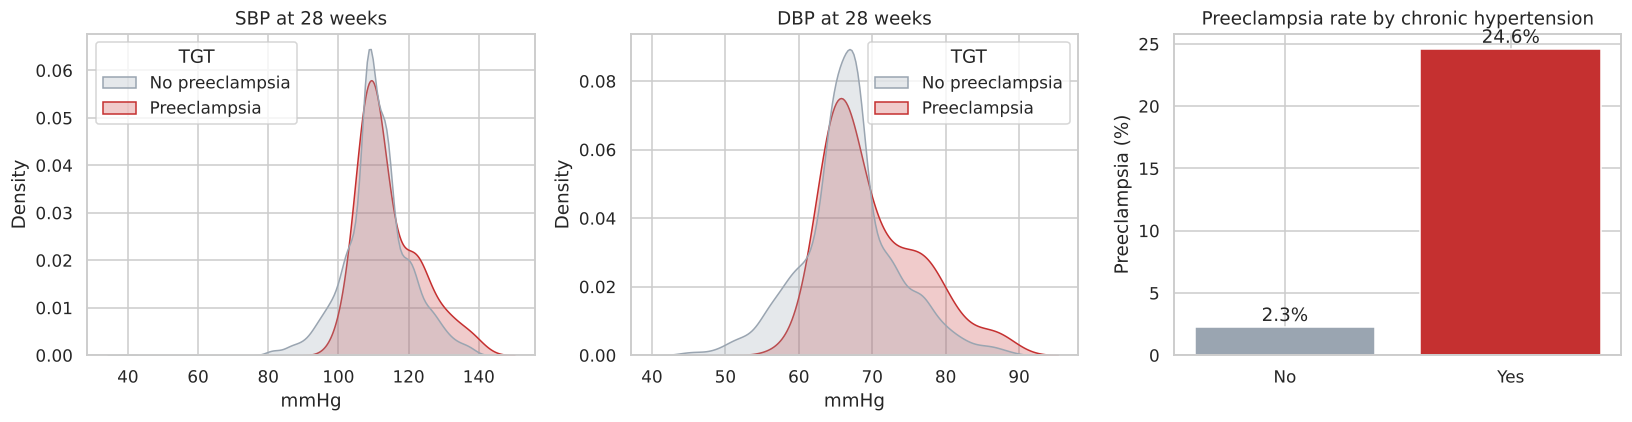

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
lab = cohort["TGT"].map({0: "No preeclampsia", 1: "Preeclampsia"})
pal = {"No preeclampsia": "#9aa5b1", "Preeclampsia": "#c53030"}
for ax, col in zip(axes[:2], ["SBP", "DBP"]):
    sns.kdeplot(x=cohort[col], hue=lab, common_norm=False, fill=True, palette=pal, ax=ax)
    ax.set_title(f"{col} at 28 weeks"); ax.set_xlabel("mmHg")
rate = cohort.groupby("chronic_hypertension")["TGT"].mean() * 100
axes[2].bar(["No", "Yes"], rate.values, color=["#9aa5b1", "#c53030"])
for i, v in enumerate(rate.values):
    axes[2].text(i, v + 0.5, f"{v:.1f}%", ha="center")
axes[2].set_title("Preeclampsia rate by chronic hypertension"); axes[2].set_ylabel("Preeclampsia (%)")
plt.tight_layout(); plt.show()

## 9. Development and test sets

The eligible cohort was divided once into a development set (75%) and a held-out test set (25%), stratified by outcome. The development set is used for model training, tuning and comparison; the test set is used only once, for the final evaluation (Section 15). A 25% test fraction was chosen to retain a sufficient number of cases for evaluation. All visits belonging to a participant profile in the test set are excluded from every training set, including the additional visits used by the proposed method.

In [12]:
dev, test = train_test_split(cohort, test_size=0.25, stratify=cohort["TGT"], random_state=SEED)
X_dev, y_dev = dev[FEATURES], dev["TGT"]
X_test, y_test = test[FEATURES], test["TGT"]
test_profiles = set(test["profile"])
print(f"Development: {len(dev)} women, {y_dev.sum()} cases | Test: {len(test)} women, {y_test.sum()} cases")

Development: 1878 women, 53 cases | Test: 626 women, 17 cases


## 10. Evaluation protocol

Model performance in the development set was estimated with nested cross-validation:
- **Outer loop:** stratified 5-fold cross-validation repeated five times, giving 25 train–validation splits. The same splits are used for every model, allowing paired comparisons.
- **Inner loop:** stratified 3-fold cross-validation within each outer training set, used to select hyperparameters. Validation data are therefore never used for tuning.

The primary performance measure is the area under the precision–recall curve (PR-AUC, computed as average precision), which is more informative than ROC-AUC when the outcome is rare; its value for a non-informative model equals the outcome prevalence. ROC-AUC and the Brier score are reported as secondary measures. Paired differences across the 25 splits are assessed with the corrected resampled t-test of Nadeau and Bengio (2003), which accounts for the overlap between training sets in repeated cross-validation.

In [13]:
outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
SPLITS = list(outer_cv.split(X_dev, y_dev))
N_TRAIN, N_VAL = len(SPLITS[0][0]), len(SPLITS[0][1])

def corrected_ttest(a, b, n_train=N_TRAIN, n_test=N_VAL):
    """Nadeau & Bengio (2003) corrected resampled t-test; returns the two-sided p-value."""
    d = np.asarray(a) - np.asarray(b); k = len(d)
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1))
    return 2 * stats.t.sf(abs(t), k - 1)

print(len(SPLITS), "outer splits; approximately", N_TRAIN, "training and", N_VAL, "validation women each")

25 outer splits; approximately 1502 training and 376 validation women each


## 11. Baseline classifiers

Seven classifiers were trained on the 28-week visit of each development woman. Each model was embedded in an identical pipeline consisting of median imputation, standardisation and the classifier, fitted within each training fold to prevent information leakage. Class weights inversely proportional to class frequency were applied where supported. Hyperparameters were selected by the inner cross-validation loop, maximising PR-AUC, from the following grids:

| Model | Hyperparameter grid |
| --- | --- |
| Logistic Regression | C ∈ {0.01, 0.1, 1}; balanced class weights |
| Decision Tree | maximum depth ∈ {3, 5}; minimum leaf size ∈ {10, 30}; balanced class weights |
| Random Forest (300 trees) | maximum depth ∈ {4, 8}; minimum leaf size ∈ {5, 20}; balanced class weights |
| Support Vector Machine (RBF kernel) | C ∈ {0.1, 1}; γ ∈ {scale, 0.01}; balanced class weights; Platt-scaled probabilities |
| K-Nearest Neighbours | k ∈ {15, 45}; weighting ∈ {uniform, distance} |
| Gaussian Naive Bayes | variance smoothing ∈ {10⁻⁹, 10⁻³} |
| Gradient Boosting | number of trees ∈ {100, 300}; maximum depth ∈ {2, 3}; learning rate 0.05 |

Functions: `base_pipeline` defines the shared preprocessing; `tuned` wraps a model in the inner-loop grid search; `fold_scores` computes ROC-AUC, PR-AUC and the Brier score; `run_fold` trains and evaluates one model on one outer split and stores the selected hyperparameters and out-of-fold predictions.

In [14]:
def base_pipeline(clf):
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("clf", clf)])

MODELS = {
    "Logistic Regression": (LogisticRegression(max_iter=5000, class_weight="balanced"), {"clf__C": [0.01, 0.1, 1]}),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
                      {"clf__max_depth": [3, 5], "clf__min_samples_leaf": [10, 30]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=SEED),
                      {"clf__max_depth": [4, 8], "clf__min_samples_leaf": [5, 20]}),
    "SVM": (SVC(probability=True, class_weight="balanced", random_state=SEED),
            {"clf__C": [0.1, 1], "clf__gamma": ["scale", 0.01]}),
    "KNN": (KNeighborsClassifier(), {"clf__n_neighbors": [15, 45], "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": (GaussianNB(), {"clf__var_smoothing": [1e-9, 1e-3]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=SEED),
                          {"clf__n_estimators": [100, 300], "clf__max_depth": [2, 3], "clf__learning_rate": [0.05]}),
}
SHORT = {"Logistic Regression": "LR", "Decision Tree": "DT", "Random Forest": "RF", "SVM": "SVM",
         "KNN": "KNN", "Naive Bayes": "NB", "Gradient Boosting": "GB"}

def tuned(name):
    clf, grid = MODELS[name]
    return GridSearchCV(base_pipeline(clone(clf)), grid, scoring="average_precision", cv=inner_cv)

def fold_scores(y_true, p):
    return {"roc_auc": roc_auc_score(y_true, p), "pr_auc": average_precision_score(y_true, p),
            "brier": brier_score_loss(y_true, p)}

def run_fold(name, tr, va):
    m = tuned(name).fit(X_dev.iloc[tr], y_dev.iloc[tr])
    p = m.predict_proba(X_dev.iloc[va])[:, 1]
    return {**fold_scores(y_dev.iloc[va], p), "params": m.best_params_, "va": va, "p": p}

cv_results = {}
for name in MODELS:
    t0 = time.time()
    cv_results[name] = Parallel(n_jobs=-1)(delayed(run_fold)(name, tr, va) for tr, va in SPLITS)
    print(f"{name:20s} completed in {time.time() - t0:5.0f} s")

Logistic Regression  completed in     4 s
Decision Tree        completed in     3 s
Random Forest        completed in   113 s
SVM                  completed in    34 s
KNN                  completed in     3 s
Naive Bayes          completed in     1 s
Gradient Boosting    completed in    87 s


In [15]:
def summary_table(results):
    rows = []
    for name, folds in results.items():
        r = {"Model": name}
        for k, lab in [("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC"), ("brier", "Brier")]:
            v = np.array([f[k] for f in folds]); r[lab] = f"{v.mean():.3f} ± {v.std():.3f}"; r[f"_{k}"] = v.mean()
        rows.append(r)
    return pd.DataFrame(rows).sort_values("_pr_auc", ascending=False)

baseline_table = summary_table(cv_results)
print(f"PR-AUC of a non-informative model (prevalence): {y_dev.mean():.3f}")
baseline_table.drop(columns=[c for c in baseline_table if c.startswith("_")])

PR-AUC of a non-informative model (prevalence): 0.028


,Model,ROC-AUC,PR-AUC,Brier
0,Logistic Regression,0.761 ± 0.067,0.248 ± 0.094,0.133 ± 0.016
6,Gradient Boosting,0.791 ± 0.084,0.221 ± 0.090,0.027 ± 0.004
3,SVM,0.745 ± 0.068,0.129 ± 0.072,0.027 ± 0.001
4,KNN,0.650 ± 0.077,0.121 ± 0.071,0.028 ± 0.002
2,Random Forest,0.764 ± 0.068,0.113 ± 0.050,0.097 ± 0.027
1,Decision Tree,0.654 ± 0.089,0.104 ± 0.050,0.160 ± 0.021
5,Naive Bayes,0.626 ± 0.089,0.081 ± 0.034,0.526 ± 0.202


## 12. Selection of the reference model

The baseline with the highest mean PR-AUC across the 25 outer splits was designated the reference model for the proposed method. This choice was fixed before any multi-time-point model was evaluated. For each classifier, the hyperparameter combination most frequently selected by the inner loop is recorded; these values are reused without further tuning when the classifier is trained with the proposed method, so that any difference in performance reflects the training data rather than additional tuning.

In [16]:
def modal_params(name):
    """Hyperparameters most frequently selected across the 25 inner searches."""
    counts = pd.Series([str(f["params"]) for f in cv_results[name]]).value_counts()
    return eval(counts.index[0]), counts

best_name = baseline_table.iloc[0]["Model"]
best_params, chosen = modal_params(best_name)
PROPOSED = f"MTP-{SHORT[best_name]} (proposed)"
print("Reference model:", best_name)
print("Hyperparameters selected in the 25 inner searches:"); print(chosen.to_string())
print("Most frequent selection (used for the proposed model):", best_params)

Reference model: Logistic Regression
Hyperparameters selected in the 25 inner searches:
{'clf__C': 0.01}    11
{'clf__C': 1}       10
{'clf__C': 0.1}      4
Most frequent selection (used for the proposed model): {'clf__C': 0.01}


## 13. Proposed method: multi-time-point (MTP) training

Conventional development of a screening model uses one record per participant at the screening time point. In this cohort that provides approximately 42 preeclampsia cases per training fold. However, the training participants were also observed at other antenatal visits (weeks 25–34), each of which records the same features and is linked to the same eventual outcome.

**Multi-time-point (MTP) training** fits the classifier on all eligible observations from every available time point of the training participants, while predictions continue to be made from the screening time point only. The classifier, its hyperparameters and its features are unchanged; only the training set is enlarged, from approximately 1,500 records with 42 cases to approximately 28,600 records with 856 case observations per fold. The approach is related to the stacked landmark ("supermodel") approach in dynamic prediction (van Houwelingen, 2007), but the time point is deliberately not included as a feature.

The following safeguards prevent information leakage:
1. Observations of any participant in the validation fold or the test set are excluded from training.
2. Every training observation satisfies the same eligibility rule (SBP < 140 and DBP < 90 mmHg).
3. Gestational week is not used as a feature; all evaluated predictions use the 28-week visit.

The proposed model (MTP applied to the reference model) is evaluated on the same 25 outer splits as the baselines. An ablation restricts training to weeks 25–28, the visits at or before the screening time point, to determine whether later observations contribute to any improvement.

Functions: `mtp_model` builds a classifier with fixed hyperparameters inside the shared pipeline; `run_mtp_fold` assembles the multi-time-point training set for one outer split, excluding validation participants, trains the model and evaluates it at the 28-week visit.

In [17]:
pool = pooled_visits[~pooled_visits["profile"].isin(test_profiles)]     # test participants never used for training

def mtp_model(name=None, params=None):
    name, params = (name or best_name), (params or best_params)
    clf = clone(MODELS[name][0]).set_params(**{k.replace("clf__", ""): v for k, v in params.items()})
    return base_pipeline(clf)

def run_mtp_fold(tr, va, weeks=range(25, 35), name=None, params=None, max_train=None):
    val_profiles = set(dev.iloc[va]["profile"])
    train_rows = pool[pool["PREG_WK"].isin(weeks) & ~pool["profile"].isin(val_profiles)]
    if max_train and len(train_rows) > max_train:      # stratified subsample (used for SVM only)
        train_rows = train_test_split(train_rows, train_size=max_train, stratify=train_rows["TGT"],
                                      random_state=SEED)[0]
    m = mtp_model(name, params).fit(train_rows[FEATURES], train_rows["TGT"])
    p = m.predict_proba(X_dev.iloc[va])[:, 1]
    return {**fold_scores(y_dev.iloc[va], p), "va": va, "p": p,
            "n_train": len(train_rows), "cases_train": int(train_rows["TGT"].sum())}

ABLATION = f"MTP-{SHORT[best_name]} ablation (weeks 25–28)"
for label, weeks in [(PROPOSED, range(25, 35)), (ABLATION, range(25, 29))]:
    t0 = time.time()
    cv_results[label] = Parallel(n_jobs=-1)(delayed(run_mtp_fold)(tr, va, weeks) for tr, va in SPLITS)
    f = cv_results[label]
    print(f"{label:36s} {time.time() - t0:5.0f} s | training observations per fold ~{np.mean([x['n_train'] for x in f]):,.0f}, "
          f"case observations ~{np.mean([x['cases_train'] for x in f]):.0f}")
print(f"Baseline training data per fold: ~{N_TRAIN} women, ~{int(y_dev.mean() * N_TRAIN)} cases")

MTP-LR (proposed)                        4 s | training observations per fold ~28,606, case observations ~856
MTP-LR ablation (weeks 25–28)            2 s | training observations per fold ~7,632, case observations ~213
Baseline training data per fold: ~1502 women, ~42 cases


In [18]:
primary_table = summary_table({k: cv_results[k] for k in list(MODELS) + [PROPOSED, ABLATION]})
for k, lab in (("pr_auc", "PR-AUC"), ("roc_auc", "ROC-AUC")):
    primary_table[f"p vs {best_name} ({lab})"] = [
        np.nan if n == best_name else corrected_ttest([f[k] for f in cv_results[n]], [f[k] for f in cv_results[best_name]])
        for n in primary_table["Model"]]
primary_table.drop(columns=[c for c in primary_table if c.startswith("_")]).round(3)

,Model,ROC-AUC,PR-AUC,Brier,p vs Logistic Regression (PR-AUC),p vs Logistic Regression (ROC-AUC)
7,MTP-LR (proposed),0.814 ± 0.083,0.309 ± 0.101,0.141 ± 0.009,0.107,0.089
0,Logistic Regression,0.761 ± 0.067,0.248 ± 0.094,0.133 ± 0.016,NaN,NaN
8,MTP-LR ablation (weeks 25–28),0.788 ± 0.074,0.242 ± 0.088,0.177 ± 0.010,0.844,0.266
6,Gradient Boosting,0.791 ± 0.084,0.221 ± 0.090,0.027 ± 0.004,0.589,0.434
3,SVM,0.745 ± 0.068,0.129 ± 0.072,0.027 ± 0.001,0.007,0.633
4,KNN,0.650 ± 0.077,0.121 ± 0.071,0.028 ± 0.002,0.022,0.030
2,Random Forest,0.764 ± 0.068,0.113 ± 0.050,0.097 ± 0.027,0.009,0.938
1,Decision Tree,0.654 ± 0.089,0.104 ± 0.050,0.160 ± 0.021,0.011,0.061
5,Naive Bayes,0.626 ± 0.089,0.081 ± 0.034,0.526 ± 0.202,0.002,0.020


## 14. Secondary analysis: MTP training across all seven classifiers

To assess whether the benefit of MTP training depends on the learning algorithm, the method was applied to each of the seven classifiers, using each classifier's most frequently selected hyperparameters (Section 12) and the same 25 outer splits. Each MTP model is compared with its own baseline. This analysis is secondary: the proposed model was pre-specified as MTP applied to the reference model, and is not replaced if another MTP model performs better. Because the computational cost of support vector machines increases steeply with sample size, the SVM was trained on a stratified random subsample of 10,000 observations per fold.

In [19]:
mtp_all = {}
for name in MODELS:
    label = PROPOSED if name == best_name else f"MTP-{SHORT[name]}"
    if name != best_name:
        params, _ = modal_params(name)
        t0 = time.time()
        cv_results[label] = Parallel(n_jobs=-1)(
            delayed(run_mtp_fold)(tr, va, range(25, 35), name, params, 10_000 if name == "SVM" else None)
            for tr, va in SPLITS)
        print(f"{label:10s} completed in {time.time() - t0:5.0f} s")
    mtp_all[name] = label

rows = []
for name, label in mtp_all.items():
    b, m = cv_results[name], cv_results[label]
    rows.append({"Classifier": name,
                 "Baseline PR-AUC": np.mean([f["pr_auc"] for f in b]), "MTP PR-AUC": np.mean([f["pr_auc"] for f in m]),
                 "p (PR-AUC)": corrected_ttest([f["pr_auc"] for f in m], [f["pr_auc"] for f in b]),
                 "Baseline ROC-AUC": np.mean([f["roc_auc"] for f in b]), "MTP ROC-AUC": np.mean([f["roc_auc"] for f in m]),
                 "p (ROC-AUC)": corrected_ttest([f["roc_auc"] for f in m], [f["roc_auc"] for f in b])})
all_mtp_table = pd.DataFrame(rows)
all_mtp_table["Change in PR-AUC"] = all_mtp_table["MTP PR-AUC"] - all_mtp_table["Baseline PR-AUC"]
print("Classifiers improved by MTP training (PR-AUC):", int((all_mtp_table["Change in PR-AUC"] > 0).sum()), "of 7")
all_mtp_table.sort_values("MTP PR-AUC", ascending=False).round(3)

MTP-DT     completed in     5 s
MTP-RF     completed in    62 s
MTP-SVM    completed in   312 s
MTP-KNN    completed in     4 s
MTP-NB     completed in     4 s
MTP-GB     completed in    84 s
Classifiers improved by MTP training (PR-AUC): 7 of 7


,Classifier,Baseline PR-AUC,MTP PR-AUC,p (PR-AUC),Baseline ROC-AUC,MTP ROC-AUC,p (ROC-AUC),Change in PR-AUC
2,Random Forest,0.113,0.324,0.001,0.764,0.805,0.223,0.210
0,Logistic Regression,0.248,0.309,0.107,0.761,0.814,0.089,0.061
6,Gradient Boosting,0.221,0.305,0.068,0.791,0.785,0.890,0.084
4,KNN,0.121,0.233,0.049,0.650,0.737,0.090,0.112
3,SVM,0.129,0.215,0.047,0.745,0.792,0.175,0.085
1,Decision Tree,0.104,0.193,0.081,0.654,0.712,0.392,0.090
5,Naive Bayes,0.081,0.126,0.093,0.626,0.687,0.280,0.045


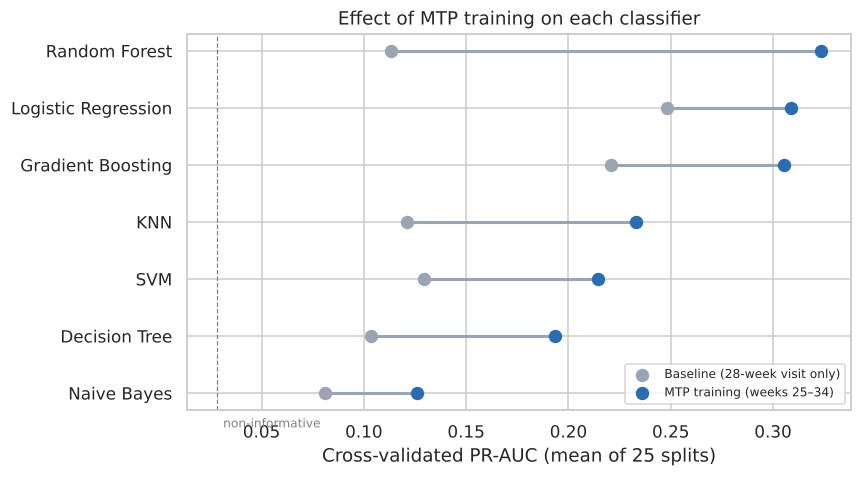

In [20]:
order = all_mtp_table.sort_values("MTP PR-AUC")["Classifier"]
fig, ax = plt.subplots(figsize=(8, 4.5))
yy = np.arange(len(order))
b_vals = all_mtp_table.set_index("Classifier").loc[order, "Baseline PR-AUC"]
m_vals = all_mtp_table.set_index("Classifier").loc[order, "MTP PR-AUC"]
ax.hlines(yy, b_vals, m_vals, color="#9aa5b1", lw=2)
ax.scatter(b_vals, yy, color="#9aa5b1", s=60, label="Baseline (28-week visit only)", zorder=3)
ax.scatter(m_vals, yy, color="#2b6cb0", s=60, label="MTP training (weeks 25–34)", zorder=3)
ax.axvline(y_dev.mean(), color="grey", ls="--", lw=0.8)
ax.text(y_dev.mean() + 0.003, -0.6, "non-informative", fontsize=8, color="grey")
ax.set_yticks(yy); ax.set_yticklabels(order)
ax.set(xlabel="Cross-validated PR-AUC (mean of 25 splits)", title="Effect of MTP training on each classifier")
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

## 15. Evaluation on the held-out test set

All models were refitted on the complete development set and evaluated once on the test set. Baselines were re-tuned by inner cross-validation on the development set; MTP models were trained on all eligible observations (weeks 25–34) of non-test participants, using the hyperparameters described above. Confidence intervals (95%) were obtained from 2,000 stratified bootstrap resamples of the test set. ROC-AUCs of each MTP model and its baseline were compared with DeLong's test. Because the test set contains few cases, these estimates are less precise than the cross-validated estimates, and both are reported.

In [21]:
final_models, test_pred = {}, {}
for name in MODELS:
    final_models[name] = tuned(name).fit(X_dev, y_dev)
    test_pred[name] = final_models[name].predict_proba(X_test)[:, 1]

mtp_train = pool[pool["PREG_WK"].between(25, 34)]
print(f"MTP final training set: {len(mtp_train):,} observations, {int(mtp_train['TGT'].sum())} case observations")
for name, label in mtp_all.items():
    params = best_params if name == best_name else modal_params(name)[0]
    rows_ = mtp_train
    if name == "SVM":
        rows_ = train_test_split(mtp_train, train_size=10_000, stratify=mtp_train["TGT"], random_state=SEED)[0]
    final_models[label] = mtp_model(name, params).fit(rows_[FEATURES], rows_["TGT"])
    test_pred[label] = final_models[label].predict_proba(X_test)[:, 1]

rng = np.random.default_rng(SEED)
pos, neg = np.where(y_test.values == 1)[0], np.where(y_test.values == 0)[0]
boot_idx = [np.r_[rng.choice(pos, len(pos)), rng.choice(neg, len(neg))] for _ in range(2000)]

def with_ci(metric, p):
    vals = [metric(y_test.values[i], p[i]) for i in boot_idx]
    return f"{metric(y_test.values, p):.3f} ({np.percentile(vals, 2.5):.3f}–{np.percentile(vals, 97.5):.3f})"

test_table = pd.DataFrame([{"Model": n, "ROC-AUC (95% CI)": with_ci(roc_auc_score, p),
                            "PR-AUC (95% CI)": with_ci(average_precision_score, p),
                            "Brier": round(brier_score_loss(y_test, p), 4)} for n, p in test_pred.items()])
print(f"Test set: {len(y_test)} women, {int(y_test.sum())} cases (non-informative PR-AUC = {y_test.mean():.3f})")
test_table

MTP final training set: 29,434 observations, 878 case observations
Test set: 626 women, 17 cases (non-informative PR-AUC = 0.027)


,Model,ROC-AUC (95% CI),PR-AUC (95% CI),Brier
0,Logistic Regression,0.756 (0.607–0.896),0.324 (0.138–0.557),0.1437
1,Decision Tree,0.671 (0.547–0.794),0.170 (0.048–0.388),0.1571
2,Random Forest,0.639 (0.495–0.775),0.176 (0.040–0.366),0.1460
3,SVM,0.744 (0.619–0.868),0.134 (0.061–0.313),0.0254
4,KNN,0.651 (0.505–0.792),0.128 (0.033–0.299),0.0258
5,Naive Bayes,0.735 (0.605–0.853),0.094 (0.048–0.191),0.2586
6,Gradient Boosting,0.685 (0.541–0.826),0.126 (0.056–0.315),0.0263
7,MTP-LR (proposed),0.764 (0.615–0.901),0.293 (0.124–0.533),0.1364
8,MTP-DT,0.633 (0.484–0.779),0.161 (0.050–0.388),0.1596
9,MTP-RF,0.793 (0.669–0.900),0.346 (0.153–0.608),0.1744


In [22]:
def delong_test(y, p1, p2):
    """DeLong et al. (1988) test for two correlated ROC-AUCs; returns (auc1, auc2, p-value)."""
    y = np.asarray(y)
    def components(p):
        ps, ns = p[y == 1], p[y == 0]
        v10 = np.array([(s > ns).mean() + 0.5 * (s == ns).mean() for s in ps])
        v01 = np.array([(ps > s).mean() + 0.5 * (ps == s).mean() for s in ns])
        return v10, v01
    a10, a01 = components(p1); b10, b01 = components(p2)
    s10 = np.cov(np.vstack([a10, b10])); s01 = np.cov(np.vstack([a01, b01]))
    var = (s10[0, 0] + s10[1, 1] - 2 * s10[0, 1]) / len(a10) + (s01[0, 0] + s01[1, 1] - 2 * s01[0, 1]) / len(a01)
    z = (a10.mean() - b10.mean()) / np.sqrt(var)
    return a10.mean(), b10.mean(), 2 * stats.norm.sf(abs(z))

delong_rows = []
for name, label in mtp_all.items():
    a1, a2, p = delong_test(y_test, test_pred[label], test_pred[name])
    delong_rows.append({"Classifier": name, "Baseline ROC-AUC": a2, "MTP ROC-AUC": a1, "DeLong p": p})
pd.DataFrame(delong_rows).round(3)

,Classifier,Baseline ROC-AUC,MTP ROC-AUC,DeLong p
0,Logistic Regression,0.756,0.764,0.753
1,Decision Tree,0.671,0.633,0.725
2,Random Forest,0.639,0.793,0.019
3,SVM,0.744,0.804,0.093
4,KNN,0.651,0.758,0.123
5,Naive Bayes,0.735,0.747,0.811
6,Gradient Boosting,0.685,0.784,0.024


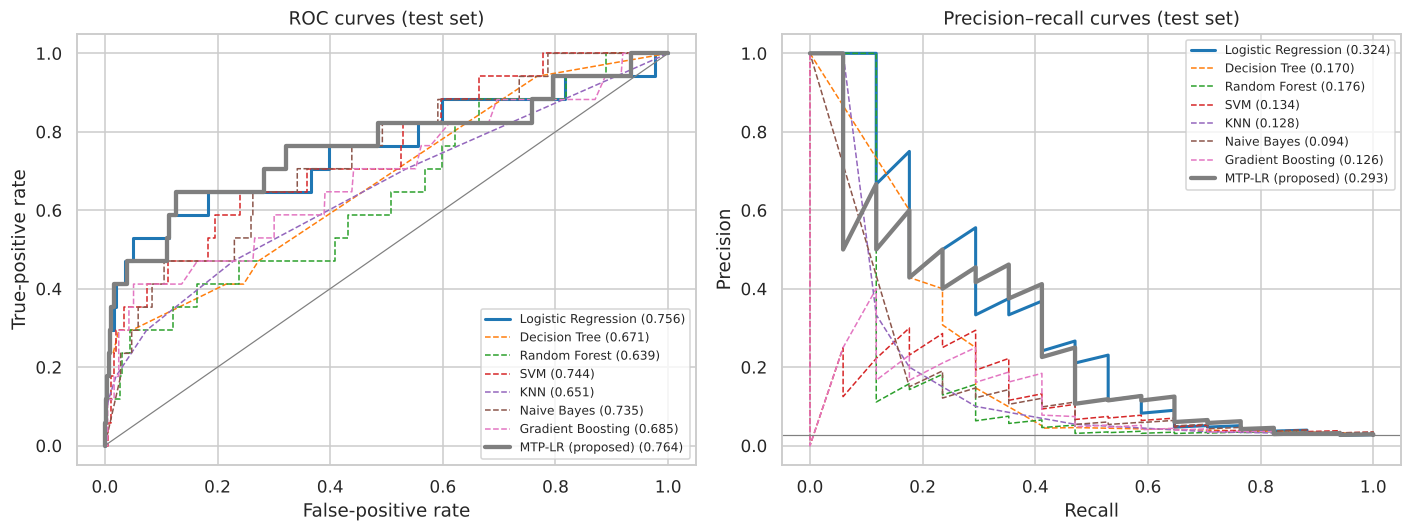

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
shown = list(MODELS) + [PROPOSED]
colors = dict(zip(shown, sns.color_palette("tab10", len(shown))))
for name in shown:
    p = test_pred[name]
    lw, ls = (2.8, "-") if name == PROPOSED else ((2, "-") if name == best_name else (1, "--"))
    fpr, tpr, _ = roc_curve(y_test, p); prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=lw, ls=ls, color=colors[name], label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rec, prec, lw=lw, ls=ls, color=colors[name], label=f"{name} ({average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", lw=0.8); axes[1].axhline(y_test.mean(), color="grey", lw=0.8)
axes[0].set(title="ROC curves (test set)", xlabel="False-positive rate", ylabel="True-positive rate")
axes[1].set(title="Precision–recall curves (test set)", xlabel="Recall", ylabel="Precision")
for ax in axes: ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "upper right")
plt.tight_layout(); plt.show()

## 16. Screening threshold and confusion matrices

To translate risk scores into enrolment decisions, a screening rule that selects the 10% of eligible women with the highest predicted risk was applied. For each model, the threshold was set at the 90th percentile of its out-of-fold predicted risks in the development set (averaged over the five cross-validation repeats) and applied unchanged to the test set. A fixed selection fraction reflects a trial with limited enrolment capacity and allows models to be compared at equal screening workload. Recall (sensitivity), precision (positive predictive value), specificity and F1-score are reported.

In [24]:
def dev_threshold(name):
    folds = cv_results[name]
    oof = pd.concat([pd.Series(f["p"], index=f["va"]) for f in folds]).groupby(level=0).mean()
    return np.quantile(oof.values, 0.90)

def decision_metrics(name):
    pred = (test_pred[name] >= dev_threshold(name)).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Model": name, "Selected": int(pred.sum()), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "Recall": tp / (tp + fn), "Precision": tp / max(tp + fp, 1), "Specificity": tn / (tn + fp),
            "F1": f1_score(y_test, pred)}

decision_table = pd.DataFrame([decision_metrics(n) for n in list(MODELS) + [PROPOSED]]).round(3)
decision_table

,Model,Selected,TP,FP,FN,TN,Recall,Precision,Specificity,F1
0,Logistic Regression,92,10,82,7,527,0.588,0.109,0.865,0.183
1,Decision Tree,138,7,131,10,478,0.412,0.051,0.785,0.090
2,Random Forest,146,7,139,10,470,0.412,0.048,0.772,0.086
3,SVM,72,7,65,10,544,0.412,0.097,0.893,0.157
4,KNN,50,5,45,12,564,0.294,0.100,0.926,0.149
5,Naive Bayes,94,8,86,9,523,0.471,0.085,0.859,0.144
6,Gradient Boosting,39,7,32,10,577,0.412,0.179,0.947,0.250
7,MTP-LR (proposed),53,8,45,9,564,0.471,0.151,0.926,0.229


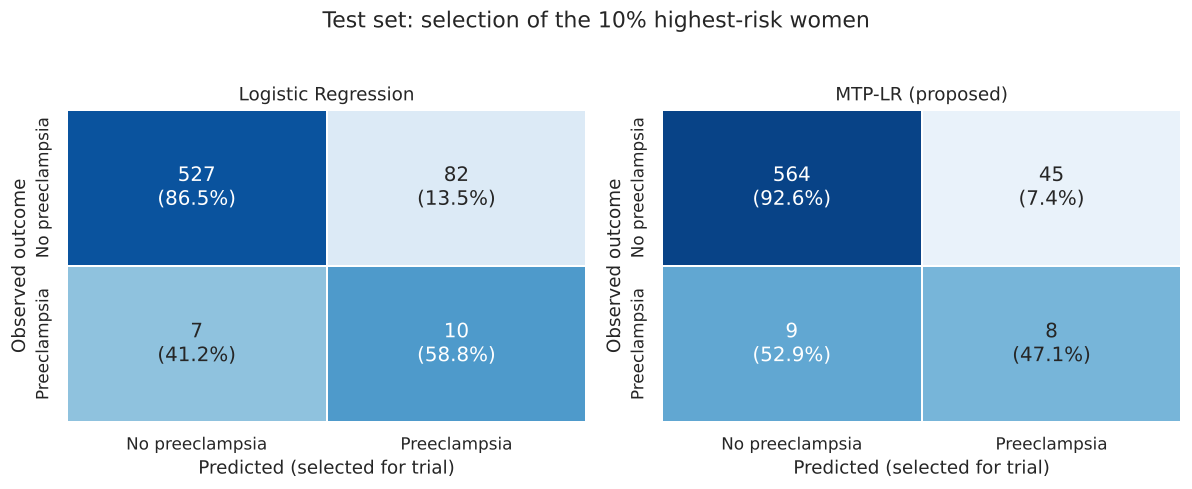

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
labels = ["No preeclampsia", "Preeclampsia"]
for ax, name in zip(axes, [best_name, PROPOSED]):
    pred = (test_pred[name] >= dev_threshold(name)).astype(int)
    cm = confusion_matrix(y_test, pred); pct = cm / cm.sum(axis=1, keepdims=True) * 100
    ann = np.array([[f"{cm[i, j]}\n({pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])
    sns.heatmap(pct, annot=ann, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=False, xticklabels=labels,
                yticklabels=labels, ax=ax, annot_kws={"size": 13}, linewidths=1, linecolor="white")
    ax.set(title=name, xlabel="Predicted (selected for trial)", ylabel="Observed outcome")
plt.suptitle("Test set: selection of the 10% highest-risk women", y=1.03)
plt.tight_layout(); plt.show()

## 17. Calibration

Calibration was assessed with calibration curves (quantile bins of predicted risk) and the Brier score. Balanced class weighting increases predicted probabilities for the minority class; this affects calibration but not the ranking of women, on which the screening rule depends.

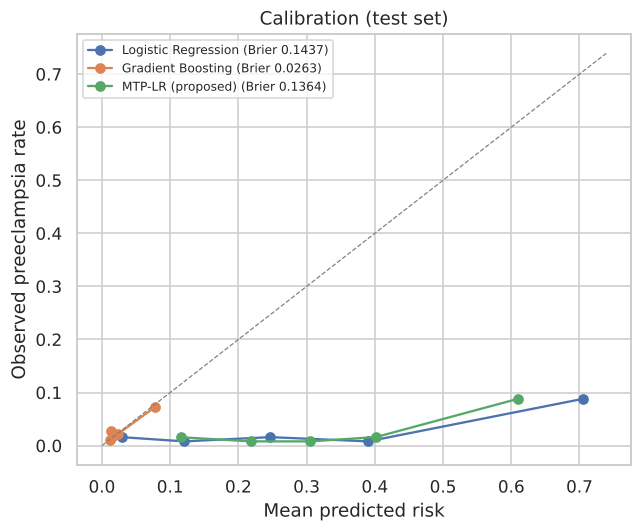

In [26]:
fig, ax = plt.subplots(figsize=(6, 5))
for name in [best_name, "Gradient Boosting", PROPOSED]:
    frac, mean_pred = calibration_curve(y_test, test_pred[name], n_bins=5, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", label=f"{name} (Brier {brier_score_loss(y_test, test_pred[name]):.4f})")
lim = max(ax.get_xlim()[1], 0.3)
ax.plot([0, lim], [0, lim], color="grey", lw=0.8, ls="--")
ax.set(xlabel="Mean predicted risk", ylabel="Observed preeclampsia rate", title="Calibration (test set)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 18. Feature importance

Feature importance for the proposed model was estimated by permutation importance on the development set: the decrease in PR-AUC when the values of one feature are randomly permuted, averaged over 10 permutations.

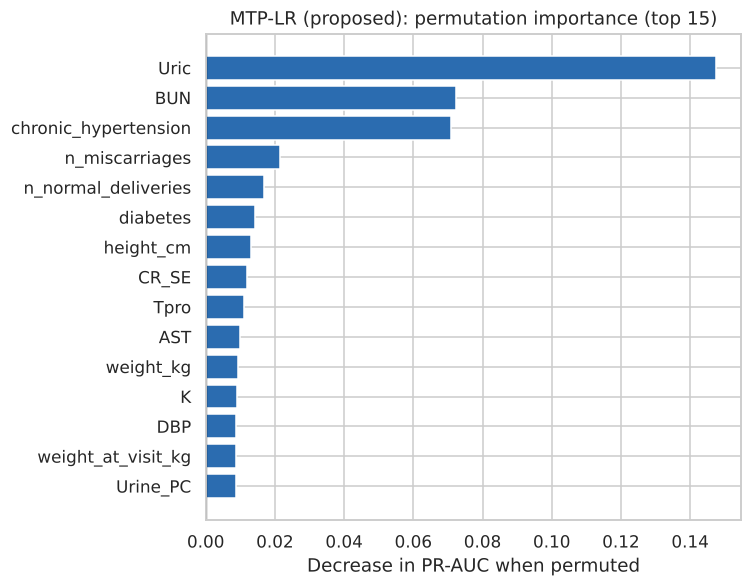

Uric                    0.1474
BUN                     0.0723
chronic_hypertension    0.0710
n_miscarriages          0.0215
n_normal_deliveries     0.0168
diabetes                0.0143
height_cm               0.0132
CR_SE                   0.0119
Tpro                    0.0112
AST                     0.0099

In [27]:
pi = permutation_importance(final_models[PROPOSED], X_dev, y_dev, scoring="average_precision",
                            n_repeats=10, random_state=SEED, n_jobs=-1)
importance = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
top = importance.head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top.index, top.values, color="#2b6cb0"); ax.axvline(0, color="black", lw=0.8)
ax.set(title=f"{PROPOSED}: permutation importance (top 15)", xlabel="Decrease in PR-AUC when permuted")
plt.tight_layout(); plt.show()
importance.head(10).round(4)

## 19. Sensitivity analyses

The comparison between the reference model and the proposed model was repeated on the same 25 outer splits under three alternative specifications:
1. **Without laboratory measurements**, because the laboratory encoding is undocumented.
2. **With medication variables**, to quantify the contribution of prescription records of unknown timing.
3. **Strict normotension**, excluding women with a blood-pressure-lowering prescription (Section 7.1) from all training and validation folds and their observations from the MTP training data.

In [28]:
def compare(feats, strict=False):
    keep = (dev["on_bp_med"] == 0).values if strict else np.ones(len(dev), bool)
    pool_ = pool[pool["on_bp_med"] == 0] if strict else pool
    def base_fold(tr, va):
        tr, va = tr[keep[tr]], va[keep[va]]
        m = GridSearchCV(base_pipeline(clone(MODELS[best_name][0])), MODELS[best_name][1],
                         scoring="average_precision", cv=inner_cv).fit(dev[feats].iloc[tr], y_dev.iloc[tr])
        return average_precision_score(y_dev.iloc[va], m.predict_proba(dev[feats].iloc[va])[:, 1])
    def mtp_fold(tr, va):
        va = va[keep[va]]
        rows_ = pool_[~pool_["profile"].isin(set(dev.iloc[va]["profile"]))]
        m = mtp_model().fit(rows_[feats], rows_["TGT"])
        return average_precision_score(y_dev.iloc[va], m.predict_proba(dev[feats].iloc[va])[:, 1])
    b = Parallel(n_jobs=-1)(delayed(base_fold)(tr, va) for tr, va in SPLITS)
    v = Parallel(n_jobs=-1)(delayed(mtp_fold)(tr, va) for tr, va in SPLITS)
    return np.mean(b), np.mean(v), corrected_ttest(v, b), int(keep.sum()), int(y_dev[keep].sum())

sens = []
for label, feats, strict in [("Main analysis", FEATURES, False),
                             ("Without laboratory measurements", [c for c in FEATURES if c not in LABS + ["lab_scaled"]], False),
                             ("With medication variables", FEATURES + MEDS, False),
                             ("Strict normotension", FEATURES, True)]:
    b, v, p, n, cases = compare(feats, strict)
    sens.append({"Analysis": label, "Development women": n, "Cases": cases, "Features": len(feats),
                 f"{best_name} PR-AUC": b, f"{PROPOSED} PR-AUC": v, "p": p})
pd.DataFrame(sens).round(3)

,Analysis,Development women,Cases,Features,Logistic Regression PR-AUC,MTP-LR (proposed) PR-AUC,p
0,Main analysis,1878,53,52,0.248,0.309,0.107
1,Without laboratory measurements,1878,53,27,0.124,0.162,0.112
2,With medication variables,1878,53,73,0.228,0.298,0.111
3,Strict normotension,1846,50,52,0.218,0.289,0.044


## 20. Summary of findings

**Study population.** After removal of 11,186 duplicate records and application of the eligibility criterion, 2,504 women normotensive at the 28-week visit were included (70 preeclampsia cases; 2.8%): 1,878 in the development set (53 cases) and 626 in the test set (17 cases). Thirty-eight eligible women (1.5%) had a prescription for a blood-pressure-lowering agent of unknown timing.

**Baseline classifiers.** Logistic Regression achieved the highest cross-validated PR-AUC (0.248; ROC-AUC 0.761) and was selected as the reference model, followed by Gradient Boosting (PR-AUC 0.221; ROC-AUC 0.791). Random Forest, Decision Tree, SVM, KNN and Naive Bayes had significantly lower PR-AUC than Logistic Regression (p ≤ 0.022).

**Proposed model.** MTP training of the reference model (MTP-LR) increased cross-validated PR-AUC from 0.248 to 0.309 (+25%; p = 0.107) and ROC-AUC from 0.761 to 0.814 (p = 0.089), using approximately 856 case observations per fold instead of 42. Restricting training to weeks 25–28 produced no improvement (PR-AUC 0.242), indicating that the benefit derives from the additional case observations at later visits.

**MTP training across classifiers.** MTP training increased PR-AUC for all seven classifiers. The largest gain was observed for Random Forest (0.113 to 0.324; p = 0.001), which achieved the highest cross-validated PR-AUC of any model; improvements for SVM (0.129 to 0.215; p = 0.047) and KNN (0.121 to 0.233; p = 0.049) were also statistically significant. In accordance with the pre-specified analysis plan, MTP-LR remains the proposed model, and MTP-RF is reported as a secondary finding.

**Held-out test set.** MTP-LR achieved ROC-AUC 0.764 (95% CI 0.615–0.901) and PR-AUC 0.293 (0.124–0.533), comparable to Logistic Regression (0.756 and 0.324; DeLong p = 0.75). MTP training significantly improved the test-set ROC-AUC of Random Forest (0.639 to 0.793; p = 0.019) and Gradient Boosting (0.685 to 0.784; p = 0.024). MTP-RF achieved the highest test-set PR-AUC (0.346; 0.153–0.608).

**Screening performance.** Selecting the 10% highest-risk women, MTP-LR selected 53 of 626 women and identified 8 of 17 cases (precision 15.1%, 5.4 times the prevalence), compared with 92 women and 10 cases (precision 10.9%) for Logistic Regression.

**Features.** Uric acid, blood urea nitrogen and chronic hypertension were the most important features, consistent with established risk markers for preeclampsia.

**Sensitivity analyses.** The improvement from MTP training was consistent without laboratory measurements (PR-AUC 0.124 to 0.162), with medication variables (0.228 to 0.298) and under strict normotension (0.218 to 0.289; p = 0.044).

**Limitations.** Participants were reconstructed without a patient identifier; the laboratory encoding and the timing of the outcome are undocumented in the source file; medication timing is unavailable; maternal age is not recorded; the test set contains 17 cases; and MTP training observations from the same woman are not independent.